In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from statsmodels.graphics.tsaplots import plot_acf
from data_fetch import GetData

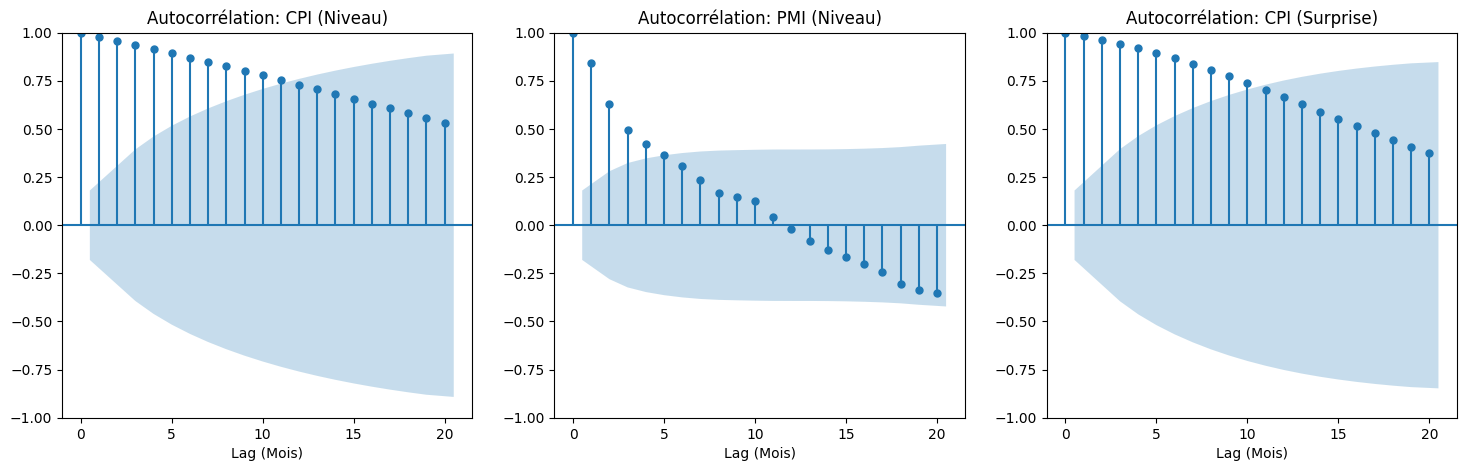

--- Coefficient de Mémoire (Autocorrélation à 1 mois) ---
CPI Level (Inflation) : 0.9997
PMI Level (Ind Prod) : 0.8449
CPI Surprise : 0.9938
EURUSD Returns (Ref) : 0.1777


In [2]:
data_map = GetData()
df_usd = data_map['USD']

series_to_test = {
    'CPI Level (Inflation)': df_usd['CPI_Actual'],
    'PMI Level (Ind Prod)': df_usd['PMI_Actual'],
    'CPI Surprise': df_usd['CPI_Actual'] - df_usd['CPI_Consensus'],
    'EURUSD Returns (Ref)': df_usd['PMI_Actual'].pct_change() 
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_acf(series_to_test['CPI Level (Inflation)'].dropna(), lags=20, ax=axes[0], title='Autocorrélation: CPI (Niveau)')
axes[0].set_xlabel('Lag (Mois)')

plot_acf(series_to_test['PMI Level (Ind Prod)'].dropna(), lags=20, ax=axes[1], title='Autocorrélation: PMI (Niveau)')
axes[1].set_xlabel('Lag (Mois)')

plot_acf(series_to_test['CPI Surprise'].dropna(), lags=20, ax=axes[2], title='Autocorrélation: CPI (Surprise)')
axes[2].set_xlabel('Lag (Mois)')

plt.show()

print("--- Coefficient de Mémoire (Autocorrélation à 1 mois) ---")
for name, series in series_to_test.items():
    ac_1 = series.autocorr(lag=1)
    print(f"{name} : {ac_1:.4f}")

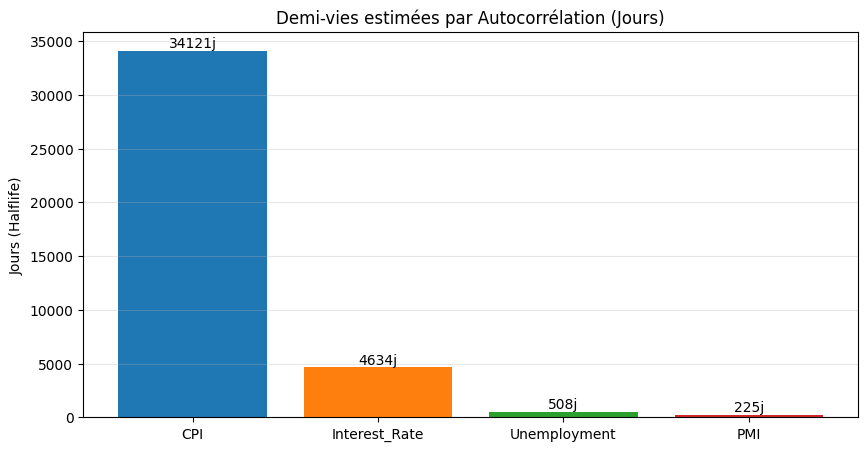

Indicator      CPI  Interest_Rate     PMI  Unemployment
Zone                                                   
AUD        38875.4         5841.4  3588.8         850.5
EUR        14841.8         6780.9     NaN        4939.6
GBP        29367.6          140.1   108.4         524.0
JPY          444.4          180.0   225.7         206.7
NZD        44394.4         5018.1   440.9         492.4
USD        62309.0         4250.7   123.4         108.1


In [3]:
def estimate_halflife_from_autocorr(data_map):
    results = []
    
    for zone, df in data_map.items():
        # On ne garde que les indicateurs originaux (sans les suffixes _Consensus)
        indicators = set([c.replace('_Actual', '').replace('_Consensus', '') 
                          for c in df.columns if '_Actual' in c])
        
        for ind in indicators:
            col_act = f"{ind}_Actual"
            if col_act not in df.columns: continue
            
            # 1. Calcul sur la donnée Native (Mensuelle)
            # On dropna() pour avoir la vraie série temporelle de publication
            series_native = df[col_act].dropna()
            
            # Si trimestriel (AUD/NZD), on ajuste le facteur temps
            is_quarterly = zone in ['AUD', 'NZD'] and ind in ['CPI', 'PMI']
            period_days = 90 if is_quarterly else 30
            
            # 2. Autocorrélation (Persistance)
            # On regarde si la valeur du mois M est corrélée à M-1
            rho = series_native.autocorr(lag=1)
            
            # 3. Conversion en Demi-Vie (Jours)
            # Formule inverse de la décroissance exponentielle
            if rho > 0 and rho < 1:
                halflife_days = -(period_days * np.log(2)) / np.log(rho)
            elif rho >= 1:
                halflife_days = 180 # Cap (Très sticky)
            else:
                halflife_days = 1 # Pas de mémoire (Bruit)
                
            results.append({
                'Zone': zone,
                'Indicator': ind,
                'Native_Autocorr': rho,
                'Implied_Halflife_Days': halflife_days
            })

    return pd.DataFrame(results)

data_map = GetData()
df_halflives = estimate_halflife_from_autocorr(data_map)

# Agrégation par type d'indicateur (Moyenne médiane pour robustesse)
df_summary = df_halflives.groupby('Indicator')['Implied_Halflife_Days'].median().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
bars = plt.bar(df_summary.index, df_summary.values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
plt.title("Demi-vies estimées par Autocorrélation (Jours)")
plt.ylabel("Jours (Halflife)")
plt.grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}j', ha='center', va='bottom')

plt.show()

print(df_halflives.pivot(index='Zone', columns='Indicator', values='Implied_Halflife_Days').round(1))